# Named Entity Recognition — simple version (LSTM vs BiLSTM vs BiGRU)

Same **flat style** as the POS notebook: no decorators, no custom metrics, just plain
Keras calls — `model1 = keras.Sequential([...])`, `model1.compile(...)`, `model1.fit(...)`.

**Task:** give every word a **BIO entity tag** (e.g. `B-per` / `I-per` for a person's name,
`B-geo` for a location, `O` for not-an-entity).

**Data:** `data/NER.zip` — one CSV with columns `Sentence #`, `Word`, `POS`, `Tag`.
The `Sentence #` column only appears on the first word of each sentence (we fill it down).

We train **three models** and compare their **accuracy**, **training time** and
**number of parameters**:

* `model1` — simple (one-direction) **LSTM**  <- the baseline
* `model2` — **BiLSTM** (reads forwards and backwards)
* `model3` — **BiGRU**


In [1]:
# 1. Imports --------------------------------------------------------------
import zipfile
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from tensorflow import keras

print("Keras / TensorFlow:", keras.__version__)


Keras / TensorFlow: 3.15.1


In [2]:
# 2. Settings -------------------------------------------------------------
PATH     = "data/NER.zip"
CSV      = "ner_datasetreference.csv"
MAXLEN   = 50    # keep at most 50 words per sentence (longer sentences are cut)
EPOCHS   = 20    # maximum number of epochs (early stopping may stop sooner)
PATIENCE = 3     # stop if validation loss does not improve for 3 epochs
BATCH    = 64


### Early stopping

We allow up to `EPOCHS = 20` epochs, but we use **early stopping**: training stops as
soon as the validation loss has not improved for `PATIENCE = 3` epochs.
`restore_best_weights=True` keeps the best version of the model.

This way we can safely set more epochs without wasting time or overfitting too much.


## 3. Load the data

We read the CSV straight from the zip with pandas, **fill the sentence numbers down**,
then group the rows into sentences (`Word` + `Tag` per sentence).

> Some words contain non-UTF-8 bytes, so we read with `encoding_errors="replace"`.


In [3]:
# 3. Load the CSV and group it into sentences ----------------------------
df = pd.read_csv(zipfile.ZipFile(PATH).open(CSV),
                 encoding="utf-8", encoding_errors="replace")

df["Sentence #"] = df["Sentence #"].ffill()   # fill down "Sentence: N"
df = df.dropna(subset=["Word"])               # drop empty rows

all_words = [g["Word"].tolist()  for _, g in df.groupby("Sentence #", sort=False)]
all_tags  = [g["Tag"].tolist()   for _, g in df.groupby("Sentence #", sort=False)]

print("sentences:", len(all_words), "  tokens:", sum(len(s) for s in all_words))
print("first sentence :", all_words[0])
print("its tags       :", all_tags[0])


sentences: 47959   tokens: 1048565
first sentence : ['Thousands', 'of', 'demonstrators', 'have', 'marched', 'through', 'London', 'to', 'protest', 'the', 'war', 'in', 'Iraq', 'and', 'demand', 'the', 'withdrawal', 'of', 'British', 'troops', 'from', 'that', 'country', '.']
its tags       : ['O', 'O', 'O', 'O', 'O', 'O', 'B-geo', 'O', 'O', 'O', 'O', 'O', 'B-geo', 'O', 'O', 'O', 'O', 'O', 'B-gpe', 'O', 'O', 'O', 'O', 'O']


## 4. Train / dev / test split

We shuffle the sentences and keep **80 % / 10 % / 10 %**.
(The full dataset is big — to keep training fast we cap the split sizes below;
remove the caps if you want to use everything.)


In [4]:
# 4. Shuffle and split -----------------------------------------------------
random.seed(0)
idx = list(range(len(all_words)))
random.shuffle(idx)

n_train = min(20000, int(0.8 * len(idx)))
n_dev   = min(3000,  int(0.1 * len(idx)))

train_words = [all_words[i] for i in idx[:n_train]]
train_tags  = [all_tags[i]  for i in idx[:n_train]]
dev_words   = [all_words[i] for i in idx[n_train:n_train + n_dev]]
dev_tags    = [all_tags[i]  for i in idx[n_train:n_train + n_dev]]
test_words  = [all_words[i] for i in idx[n_train + n_dev:n_train + 2 * n_dev]]
test_tags   = [all_tags[i]  for i in idx[n_train + n_dev:n_train + 2 * n_dev]]

print("sentences  train:", len(train_words), " dev:", len(dev_words), " test:", len(test_words))


sentences  train: 20000  dev: 3000  test: 3000


## 5. Build the word and tag dictionaries

* each word -> a number (`0` = padding, `1` = unknown word `<unk>`)
* each tag  -> a number (tag numbers start at `1`, because `0` is padding)

> We keep the original capitalisation — it is very useful for NER
> ("Apple" the company vs "apple" the fruit).


In [5]:
# 5. Dictionaries ---------------------------------------------------------
counter = Counter(w for s in train_words for w in s)
word2idx = {"<pad>": 0, "<unk>": 1}
for w, n in counter.most_common():
    if n >= 2:                       # words seen only once become <unk>
        word2idx[w] = len(word2idx)

tag_names = sorted({t for s in train_tags for t in s})
tag2idx = {t: i + 1 for i, t in enumerate(tag_names)}   # 0 is padding
idx2tag = {i: t for t, i in tag2idx.items()}

print("number of words:", len(word2idx))
print("number of tags :", len(tag2idx), tag_names)


number of words: 12967
number of tags : 17 ['B-art', 'B-eve', 'B-geo', 'B-gpe', 'B-nat', 'B-org', 'B-per', 'B-tim', 'I-art', 'I-eve', 'I-geo', 'I-gpe', 'I-nat', 'I-org', 'I-per', 'I-tim', 'O']


## 6. Turn sentences into numbers

Every sentence becomes a list of word numbers padded with `0` up to `MAXLEN`.
The tags become a list of tag numbers, also padded with `0`.


In [6]:
# 6a. Encode the training set ---------------------------------------------
X_train = np.zeros((len(train_words), MAXLEN), dtype="int32")
y_train = np.zeros((len(train_words), MAXLEN), dtype="int32")
for i in range(len(train_words)):
    for j in range(min(MAXLEN, len(train_words[i]))):
        X_train[i, j] = word2idx.get(train_words[i][j], 1)
        y_train[i, j] = tag2idx[train_tags[i][j]]
print("X_train:", X_train.shape, " y_train:", y_train.shape)


X_train: (20000, 50)  y_train: (20000, 50)


In [7]:
# 6b. Encode the dev set -------------------------------------------------
X_dev = np.zeros((len(dev_words), MAXLEN), dtype="int32")
y_dev = np.zeros((len(dev_words), MAXLEN), dtype="int32")
for i in range(len(dev_words)):
    for j in range(min(MAXLEN, len(dev_words[i]))):
        X_dev[i, j] = word2idx.get(dev_words[i][j], 1)
        y_dev[i, j] = tag2idx[dev_tags[i][j]]
print("X_dev:", X_dev.shape)


X_dev: (3000, 50)


In [8]:
# 6c. Encode the test set ------------------------------------------------
X_test = np.zeros((len(test_words), MAXLEN), dtype="int32")
y_test = np.zeros((len(test_words), MAXLEN), dtype="int32")
for i in range(len(test_words)):
    for j in range(min(MAXLEN, len(test_words[i]))):
        X_test[i, j] = word2idx.get(test_words[i][j], 1)
        y_test[i, j] = tag2idx[test_tags[i][j]]
print("X_test:", X_test.shape)


X_test: (3000, 50)


## 7. Build the models

All three are the **same** model; only the middle layer changes:

1. `model1` — `LSTM` (baseline, reads left → right only)
2. `model2` — `Bidirectional(LSTM)`
3. `model3` — `Bidirectional(GRU)`

> `mask_zero=True` tells Keras to ignore the padding.
> `N_TAGS + 1` output classes because class `0` is the padding tag.
> `return_sequences=True` gives one tag per word.


In [9]:
# 7. Model 1 = simple LSTM (baseline) ------------------------------------
V = len(word2idx)
N_TAGS = len(tag2idx) + 1     # +1 for the padding class (index 0)

model1 = keras.Sequential([
    keras.layers.Input(shape=(MAXLEN,)),
    keras.layers.Embedding(V, 64, mask_zero=True),
    keras.layers.LSTM(128, return_sequences=True),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(N_TAGS, activation="softmax"),
])
model1.compile(optimizer="adam",
               loss="sparse_categorical_crossentropy",
               metrics=["accuracy"])
model1.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 50, 64)         │       829,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 50, 128)        │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 50, 64)         │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 50, 18)         │         1,170 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 938,130 (3.58 MB)

 Trainable params: 938,130 (3.58 MB)

 Non-trainable params: 0 (0.00 B)

## 8. Train model1 (LSTM baseline)

`sample_weight` is `1` for real words and `0` for padding, so the score only counts
real words. We time the training with `time.time()`.


In [10]:
# 8. Train model 1 (early stopping) --------------------------------------
stop1 = keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE,
                                      restore_best_weights=True)
start1 = time.time()
history1 = model1.fit(
    X_train, y_train,
    sample_weight=(y_train != 0).astype("float32"),
    validation_data=(X_dev, y_dev, (y_dev != 0).astype("float32")),
    epochs=EPOCHS, batch_size=BATCH, verbose=1,
    callbacks=[stop1],
)
time1 = time.time() - start1
print("LSTM training time:", round(time1, 1), "seconds  |  epochs run:", len(history1.history["loss"]))


Epoch 1/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 15s 43ms/step - accuracy: 0.8650 - loss: 0.6592 - val_accuracy: 0.9086 - val_loss: 0.3344
Epoch 2/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 15s 46ms/step - accuracy: 0.9316 - loss: 0.2469 - val_accuracy: 0.9457 - val_loss: 0.2034
Epoch 3/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 33ms/step - accuracy: 0.9544 - loss: 0.1591 - val_accuracy: 0.9521 - val_loss: 0.1689
Epoch 4/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 32ms/step - accuracy: 0.9608 - loss: 0.1280 - val_accuracy: 0.9547 - val_loss: 0.1529
Epoch 5/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.9645 - loss: 0.1120 - val_accuracy: 0.9549 - val_loss: 0.1532
Epoch 6/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 9s 29ms/step - accuracy: 0.9669 - loss: 0.1021 - val_accuracy: 0.9559 - val_loss: 0.1510
Epoch 7/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.9693 - loss: 0.0940 - val_accuracy: 0.9559 - val_loss: 0.1539
Epoch 8/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 11s 34ms/step - accuracy: 0.9715 - loss: 0.0865 - va

In [11]:
# 9. Model 2 = BiLSTM -----------------------------------------------------
model2 = keras.Sequential([
    keras.layers.Input(shape=(MAXLEN,)),
    keras.layers.Embedding(V, 64, mask_zero=True),
    keras.layers.Bidirectional(keras.layers.LSTM(128, return_sequences=True)),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(N_TAGS, activation="softmax"),
])
model2.compile(optimizer="adam",
               loss="sparse_categorical_crossentropy",
               metrics=["accuracy"])
model2.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 50, 64)         │       829,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 50, 256)        │       197,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 50, 64)         │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 50, 18)         │         1,170 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,045,138 (3.99 MB)

 Trainable params: 1,045,138 (3.99 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# 10. Train model 2 (early stopping) -------------------------------------
stop2 = keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE,
                                      restore_best_weights=True)
start2 = time.time()
history2 = model2.fit(
    X_train, y_train,
    sample_weight=(y_train != 0).astype("float32"),
    validation_data=(X_dev, y_dev, (y_dev != 0).astype("float32")),
    epochs=EPOCHS, batch_size=BATCH, verbose=1,
    callbacks=[stop2],
)
time2 = time.time() - start2
print("BiLSTM training time:", round(time2, 1), "seconds  |  epochs run:", len(history2.history["loss"]))


Epoch 1/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 19s 53ms/step - accuracy: 0.8729 - loss: 0.5711 - val_accuracy: 0.9223 - val_loss: 0.2759
Epoch 2/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 15s 49ms/step - accuracy: 0.9464 - loss: 0.1889 - val_accuracy: 0.9538 - val_loss: 0.1576
Epoch 3/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 12s 38ms/step - accuracy: 0.9647 - loss: 0.1180 - val_accuracy: 0.9600 - val_loss: 0.1377
Epoch 4/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 15s 48ms/step - accuracy: 0.9708 - loss: 0.0949 - val_accuracy: 0.9604 - val_loss: 0.1412
Epoch 5/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 14s 44ms/step - accuracy: 0.9746 - loss: 0.0809 - val_accuracy: 0.9618 - val_loss: 0.1345
Epoch 6/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 12s 39ms/step - accuracy: 0.9779 - loss: 0.0701 - val_accuracy: 0.9609 - val_loss: 0.1384
Epoch 7/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 12s 39ms/step - accuracy: 0.9809 - loss: 0.0608 - val_accuracy: 0.9616 - val_loss: 0.1440
Epoch 8/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 13s 42ms/step - accuracy: 0.9831 - loss: 0.0533 - 

In [13]:
# 11. Model 3 = BiGRU ----------------------------------------------------
model3 = keras.Sequential([
    keras.layers.Input(shape=(MAXLEN,)),
    keras.layers.Embedding(V, 64, mask_zero=True),
    keras.layers.Bidirectional(keras.layers.GRU(128, return_sequences=True)),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(N_TAGS, activation="softmax"),
])
model3.compile(optimizer="adam",
               loss="sparse_categorical_crossentropy",
               metrics=["accuracy"])
model3.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 50, 64)         │       829,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 50, 256)        │       148,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 50, 64)         │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 50, 18)         │         1,170 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 996,498 (3.80 MB)

 Trainable params: 996,498 (3.80 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:
# 12. Train model 3 (early stopping) -------------------------------------
stop3 = keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE,
                                      restore_best_weights=True)
start3 = time.time()
history3 = model3.fit(
    X_train, y_train,
    sample_weight=(y_train != 0).astype("float32"),
    validation_data=(X_dev, y_dev, (y_dev != 0).astype("float32")),
    epochs=EPOCHS, batch_size=BATCH, verbose=1,
    callbacks=[stop3],
)
time3 = time.time() - start3
print("BiGRU training time:", round(time3, 1), "seconds  |  epochs run:", len(history3.history["loss"]))


Epoch 1/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 15s 41ms/step - accuracy: 0.8917 - loss: 0.4858 - val_accuracy: 0.9439 - val_loss: 0.2015
Epoch 2/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 13s 42ms/step - accuracy: 0.9587 - loss: 0.1414 - val_accuracy: 0.9591 - val_loss: 0.1396
Epoch 3/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 13s 42ms/step - accuracy: 0.9688 - loss: 0.1023 - val_accuracy: 0.9619 - val_loss: 0.1279
Epoch 4/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 12s 37ms/step - accuracy: 0.9733 - loss: 0.0850 - val_accuracy: 0.9612 - val_loss: 0.1298
Epoch 5/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 12s 38ms/step - accuracy: 0.9765 - loss: 0.0736 - val_accuracy: 0.9622 - val_loss: 0.1328
Epoch 6/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 12s 38ms/step - accuracy: 0.9796 - loss: 0.0639 - val_accuracy: 0.9619 - val_loss: 0.1345
BiGRU training time: 77.0 seconds  |  epochs run: 6


## 13. Compare the three models

Test accuracy (over real words), training time and number of parameters.


In [15]:
# 13. Evaluate on the test set -------------------------------------------
w_test = (y_test != 0).astype("float32")

loss1, acc1 = model1.evaluate(X_test, y_test, sample_weight=w_test, verbose=0)
loss2, acc2 = model2.evaluate(X_test, y_test, sample_weight=w_test, verbose=0)
loss3, acc3 = model3.evaluate(X_test, y_test, sample_weight=w_test, verbose=0)

print("              accuracy   time(s)   parameters")
print("LSTM     ", round(acc1, 4), "  ", round(time1, 1), "  ", model1.count_params())
print("BiLSTM   ", round(acc2, 4), "  ", round(time2, 1), "  ", model2.count_params())
print("BiGRU    ", round(acc3, 4), "  ", round(time3, 1), "  ", model3.count_params())


              accuracy   time(s)   parameters
LSTM      0.9562    101.3    938130
BiLSTM    0.9632    112.8    1045138
BiGRU     0.9634    77.0    996498


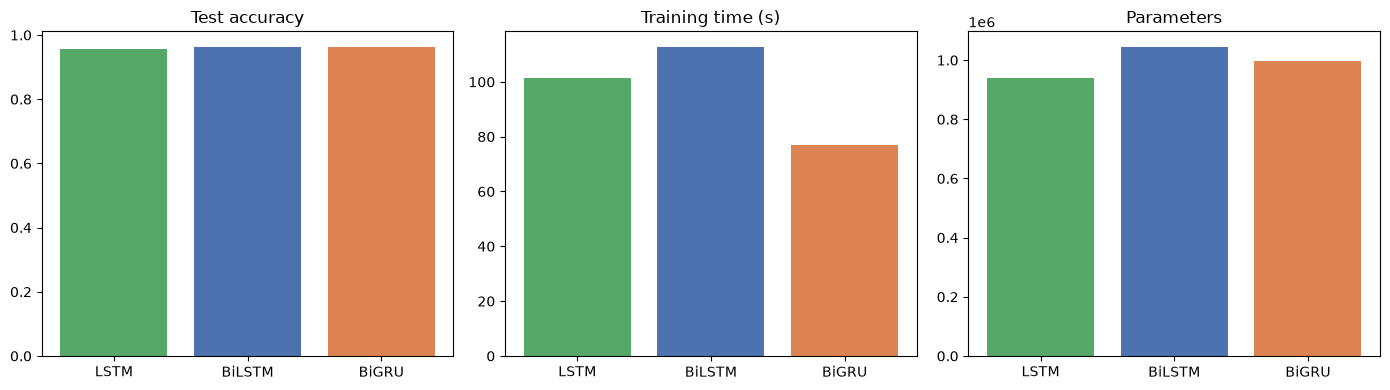

In [17]:
# 14. Simple bar charts --------------------------------------------------
names = ["LSTM", "BiLSTM", "BiGRU"]
colors = ["#55A868", "#4C72B0", "#DD8452"]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].bar(names, [acc1, acc2, acc3], color=colors);  axes[0].set_title("Test accuracy")
axes[1].bar(names, [time1, time2, time3], color=colors); axes[1].set_title("Training time (s)")
axes[2].bar(names, [model1.count_params(), model2.count_params(), model3.count_params()], color=colors)
axes[2].set_title("Parameters")
plt.tight_layout()
plt.savefig("images/ner_comparison.png", dpi=150, bbox_inches="tight")
plt.show()


## 15. Tag a new sentence

Finally, give the model a sentence and print the predicted entity tag under each word.
We use the BiLSTM (`model2`) here, but you can try `model1` or `model3`.


In [18]:
# 15. Tag one sentence with model2 ---------------------------------------
sentence = "Barack Obama was born in Hawaii and visited London in 2019 ."
words = sentence.split()

ids = np.zeros((1, MAXLEN), dtype="int32")
for i in range(len(words)):
    ids[0, i] = word2idx.get(words[i], 1)

probs = model2.predict(ids, verbose=0)[0]
predicted = [idx2tag[int(probs[i].argmax())] for i in range(len(words))]

for w, t in zip(words, predicted):
    print(f"{w:>10}  ->  {t}")


    Barack  ->  B-per
     Obama  ->  I-per
       was  ->  O
      born  ->  O
        in  ->  O
    Hawaii  ->  B-geo
       and  ->  O
   visited  ->  O
    London  ->  B-geo
        in  ->  O
      2019  ->  B-geo
         .  ->  O


## Done!

* `model1` (simple LSTM) is the **baseline**. It only reads left → right.
* **Early stopping** keeps the best model and stops training once validation loss
  stops improving, so we can set many epochs (`EPOCHS = 20`) safely.
* `model2` (BiLSTM) and `model3` (BiGRU) read the sentence in **both** directions, so
  they usually score higher — at the cost of more computation.
* Compare accuracy, time and parameters above.

**Try changing:** `EPOCHS`, `MAXLEN`, the `128` units, the `64` embedding size, or the
caps on the train/dev/test sizes in section 4 (use more data for a better model).
You can also swap `LSTM` for `SimpleRNN` in `model1` to make the baseline even simpler.
